# Introdução ao Pandas
### Leitura, limpeza, análise e visualização de dados tabulares em Python

Universidade Federal do Piauí

Este notebook acompanha a apresentação *Introdução ao Pandas*. Cada seção apresenta um conceito e, em seguida, pelo menos um exemplo executável. Execute as células em ordem, de cima para baixo (menu **Executar tudo** / *Run All*).

**Roteiro**
1. Fundamentos: o que é o Pandas, ecossistema, vantagens e limites
2. Estruturas: Series, alinhamento pelo índice e DataFrame
3. Leitura e exploração de dados
4. Seleção e filtragem
5. Limpeza: ausentes, dados errados, formatação e duplicados
6. Transformação, agregação e junção de tabelas
7. Correlação e visualização
8. Estudo de caso, boas práticas e exercícios

> Todos os exemplos usam o mesmo conjunto de dados fictício de alunos, para que você acompanhe cada transformação do início ao fim.

---
## 1. Fundamentos

### 1.1 O que é o Pandas?

- Biblioteca Python de código aberto para **manipulação e análise de dados tabulares**, carregados **em memória (RAM)**.
- Construída sobre o **NumPy**: as operações em colunas são vetorizadas e executadas em código compilado, não em laços Python.
- Integra-se ao **Matplotlib** para gráficos rápidos com `df.plot()`.
- O nome vem de *panel data* (termo da econometria) e de *Python data analysis*. Foi criado por **Wes McKinney** em 2008.

**Analogia:** pense no DataFrame como uma planilha do Excel ou uma tabela SQL que você manipula com código, de forma reprodutível.

Instalação (no terminal ou em uma célula com `!`):
```
pip install pandas matplotlib
```

In [155]:
import pandas as pd   # apelido padrão da comunidade
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("pandas:", pd.__version__)
print("numpy: ", np.__version__)
print("matplotlib :", matplotlib.__version__)

pandas: 2.2.3
numpy:  2.4.4
matplotlib : 3.10.5


### 1.2 Uma breve história

| Ano | Marco |
|---|---|
| 2008 | Início do desenvolvimento por Wes McKinney |
| 2009 | Código aberto ao público |
| 2015 | Passa a ser projeto patrocinado pela NumFOCUS |
| 2020 | Versão 1.0, API estabilizada |
| 2023 | Versão 2.0, com suporte opcional ao Apache Arrow |
| Hoje | Série 3.x: Copy-on-Write e tipo `str` como padrão para texto |

**Exemplo:** algumas mudanças da série 3.x podem ser observadas diretamente. Em versões 2.x, uma coluna de texto aparece com tipo `object`; na 3.x, aparece como `str`.

In [156]:
s = pd.Series(["Ana", "Bruno"])
print(s)
print("Versão do pandas:", pd.__version__)
print("Tipo de uma Series de texto:", s.dtype)

0      Ana
1    Bruno
dtype: object
Versão do pandas: 2.2.3
Tipo de uma Series de texto: object


### 1.3 O Pandas no ecossistema de dados

| Biblioteca | Papel |
|---|---|
| **NumPy** | Arrays numéricos e operações vetorizadas que servem de base para as colunas |
| **Matplotlib / Seaborn** | Visualização |
| **Jupyter** | Notebooks interativos para análise exploratória |
| **scikit-learn** | Aprendizado de máquina a partir de DataFrames limpos |
| **SciPy / statsmodels** | Testes estatísticos e modelos de regressão |
| **PyArrow** | Formato colunar eficiente, usado também como backend |
| **Polars, Dask, PySpark** | Alternativas para volumes que não cabem na memória |

**Exemplo:** cada coluna de um DataFrame pode ser convertida em um array NumPy, e funções NumPy podem ser aplicadas diretamente a colunas do Pandas.

In [157]:
notas = pd.Series([8.5, 7.0, 9.2, 5.8])

arr = notas.to_numpy()          # Pandas -> NumPy
print(type(arr), arr)

print(np.sqrt(notas))           # função NumPy aplicada a uma Series

<class 'numpy.ndarray'> [8.5 7.  9.2 5.8]
0    2.915476
1    2.645751
2    3.033150
3    2.408319
dtype: float64


### 1.4 Por que usar o Pandas?

**Vantagens**
- Lê dados de muitas fontes com uma linha de código
- Trata valores ausentes (`NaN`) de forma nativa
- Operações vetorizadas, muito mais rápidas que laços em Python puro
- Colunas podem ser inseridas e removidas (mutabilidade de tamanho)
- Alinhamento automático de dados pelo índice
- Agrupamentos, junções e tabelas dinâmicas no estilo SQL

**Limites**
- Os dados precisam **caber na memória RAM**; recomenda-se ter de 5 a 10 vezes o tamanho do arquivo disponível.
- Para *big data* de verdade (dezenas de GB ou mais), considere **Polars**, **DuckDB**, **Dask** ou **PySpark**.

**Exemplo:** comparando um laço Python com uma operação vetorizada sobre 1 milhão de valores.

In [158]:
import time

valores = pd.Series(np.random.default_rng(42).random(100_000_000))

print(f"Valores: {valores.describe()}")

print("")

print("Aguarde, calculando o dobro dos valores usando for...")
inicio = time.perf_counter()
dobro_laco = [v * 2 for v in valores]          # laço em Python puro
t_laco = time.perf_counter() - inicio
print("concluído.")
print(f"Laço Python:  {t_laco:.4f} s")

print("Aguarde, calculando o dobro dos valores usando vetorização...")
inicio = time.perf_counter()
dobro_vetor = valores * 2                       # operação vetorizada
t_vetor = time.perf_counter() - inicio
print("concluído.")
print(f"Vetorizado:   {t_vetor:.4f} s")

print("")
print(f"Laço Python:  {t_laco:.4f} s")
print(f"Vetorizado:   {t_vetor:.4f} s")
print(f"Aproximadamente {t_laco / t_vetor:.0f} vezes mais rápido")

Valores: count    1.000000e+08
mean     4.999929e-01
std      2.886822e-01
min      9.775333e-09
25%      2.500036e-01
50%      4.999905e-01
75%      7.500247e-01
max      1.000000e+00
dtype: float64

Aguarde, calculando o dobro dos valores usando for...
concluído.
Laço Python:  5.7147 s
Aguarde, calculando o dobro dos valores usando vetorização...
concluído.
Vetorizado:   0.1299 s

Laço Python:  5.7147 s
Vetorizado:   0.1299 s
Aproximadamente 44 vezes mais rápido


---
## 2. Estruturas de dados

### 2.1 Series: uma coluna com índice

- Array **unidimensional** que armazena dados de um único tipo (`dtype`).
- Cada valor tem um **rótulo** no índice; por padrão, 0, 1, 2…
- Corresponde a uma coluna de uma tabela.
- Suporta acesso por **rótulo** e por **posição inteira**.

In [159]:
notas = pd.Series(
    [8.5, 7.0, 9.2],
    index=["Ana", "Bruno", "Elisa"],
    name="nota",
)
notas

Ana      8.5
Bruno    7.0
Elisa    9.2
Name: nota, dtype: float64

In [160]:
print("Por rótulo  notas['Bruno']  :", notas["Bruno"])
print("Por posição notas.iloc[0]   :", notas.iloc[0])
print("Média                       :", round(notas.mean(), 4))

Por rótulo  notas['Bruno']  : 7.0
Por posição notas.iloc[0]   : 8.5
Média                       : 8.2333


In [161]:
# operações vetorizadas e filtros booleanos
print(notas * 10)
print()
print(notas[notas > 8])

Ana      85.0
Bruno    70.0
Elisa    92.0
Name: nota, dtype: float64

Ana      8.5
Elisa    9.2
Name: nota, dtype: float64


### 2.2 Alinhamento pelo índice

Ao operar duas Series, o Pandas combina os valores **pelos rótulos do índice**, e não pela posição. Rótulos presentes em apenas uma delas resultam em `NaN`.

Esse comportamento evita erros silenciosos ao juntar dados de fontes diferentes, mas pode surpreender quem está acostumado com listas ou arrays NumPy.

In [162]:
A = pd.Series([1, 2, 3], index=["a", "b", "c"])
B = pd.Series([10, 20, 30], index=["b", "c", "d"])

print(f"Series A:\n{A}\n")
print(f"Series B:\n{B}\n")

print(f"Resultado da soma (A + B):\n{A + B}\n")

Series A:
a    1
b    2
c    3
dtype: int64

Series B:
b    10
c    20
d    30
dtype: int64

Resultado da soma (A + B):
a     NaN
b    12.0
c    23.0
d     NaN
dtype: float64



Para preencher os rótulos ausentes com zero, use `add` com `fill_value`. Para somar por posição, ignore o índice com `.values`.

In [163]:
print(A.add(B, fill_value=0))
print()
print("Soma por posição:", A.values + B.values)

a     1.0
b    12.0
c    23.0
d    30.0
dtype: float64

Soma por posição: [11 22 33]


### 2.3 DataFrame: uma tabela de Series

- Estrutura **bidimensional**, com linhas e colunas.
- Cada coluna é uma Series e pode ter seu próprio tipo.
- Possui dois eixos: `index` (linhas, eixo 0) e `columns` (colunas, eixo 1).
- Suporta indexação por rótulo (`loc`) e por posição (`iloc`).
- `NaN` (*Not a Number*) marca um valor ausente; ele é ignorado por padrão em somas, médias e contagens.

Este é o DataFrame `df` usado em todos os exemplos a seguir.

In [164]:
df_alunos = pd.DataFrame({
    "nome":   ["Ana", "Bruno", "Carla", "Diego", "Elisa", "Fábio"],
    "curso":  ["Computação", "Computação", "Engenharia Civil",
               "Engenharia Civil", "Computação", "Matemática"],
    "idade":  [20, 22, 21, 23, 19, 24],
    "nota":   [8.5, 7.0, np.nan, 7.6, 9.2, 5.8],
    "cidade": ["Teresina", "Parnaíba", "Teresina",
               "Picos", "Teresina", "Floriano"],
})
df_alunos

,nome,curso,idade,nota,cidade
0,Ana,Computação,20,8.5,Teresina
1,Bruno,Computação,22,7.0,Parnaíba
2,Carla,Engenharia Civil,21,NaN,Teresina
3,Diego,Engenharia Civil,23,7.6,Picos
4,Elisa,Computação,19,9.2,Teresina
5,Fábio,Matemática,24,5.8,Floriano


In [165]:
print("Índice :", df_alunos.index)
print("Colunas:", list(df_alunos.columns))
print("Tipo da coluna 'nota':", type(df_alunos["nota"]))

Índice : RangeIndex(start=0, stop=6, step=1)
Colunas: ['nome', 'curso', 'idade', 'nota', 'cidade']
Tipo da coluna 'nota': <class 'pandas.core.series.Series'>


### 2.4 Criando DataFrames

Além do dicionário de listas (uma lista por coluna), há outras formas comuns de criar um DataFrame.

**A partir de uma lista de dicionários** (um dicionário por linha):

In [166]:
registros = [
    {"nome": "Ana", "nota": 8.5},
    {"nome": "Bruno", "nota": 7.0},
]
# Converte uma lista estruturada de registros (dicionários) em um DataFrame
pd.DataFrame(registros)

,nome,nota
0,Ana,8.5
1,Bruno,7.0


**A partir de um array NumPy:**

In [167]:
# Cria um Generator de números aleatórios com semente fixa
rng = np.random.default_rng(0)

# Cria um DataFrame com 10 linhas e 2 colunas de números aleatórios (baseado no Generator)
pd.DataFrame(rng.random((10, 2)), columns=["x", "y"])

,x,y
0,0.636962,0.269787
1,0.040974,0.016528
2,0.813270,0.912756
3,0.606636,0.729497
4,0.543625,0.935072
5,0.815854,0.002739
6,0.857404,0.033586
7,0.729655,0.175656
8,0.863179,0.541461
9,0.299712,0.422687


**Propriedades básicas:**

In [168]:
print("shape :", df_alunos.shape)      # (linhas, colunas)
print("columns:", list(df_alunos.columns))
print()
print(df_alunos.dtypes)

shape : (6, 5)
columns: ['nome', 'curso', 'idade', 'nota', 'cidade']

nome       object
curso      object
idade       int64
nota      float64
cidade     object
dtype: object


### 2.5 Principais atividades de análise com o Pandas

1. **Estruturar:** definir as Series e DataFrames que armazenarão os dados.
2. **Ler:** carregar os dados de arquivos, bancos de dados ou APIs.
3. **Limpar:** tratar células vazias, dados errados, formatos inconsistentes e duplicados.
4. **Analisar:** filtrar, agrupar, agregar e identificar correlações.
5. **Visualizar:** plotar gráficos que facilitem a interpretação.

Na prática, o fluxo não é linear: a exploração frequentemente revela novos problemas nos dados e você volta à etapa de limpeza.

**Exemplo:** as cinco etapas em miniatura.

curso
Computação          8.23
Engenharia Civil    7.60
Matemática          5.80
Name: nota, dtype: float64


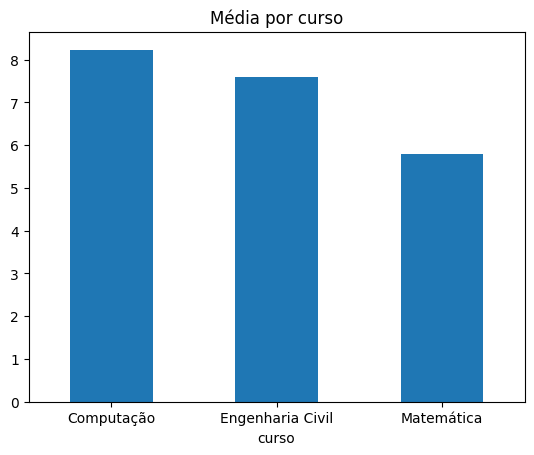

In [169]:
# 1. estruturar e 2. ler (aqui, os dados já estão em memória)
dados_alunos = df_alunos.copy()

# 3. limpar: remove alunos sem nota
dados = dados_alunos.dropna(subset=["nota"])

# 4. analisar: média de nota por curso
media_curso = dados.groupby("curso")["nota"].mean().round(2)
print(media_curso)

# 5. visualizar
media_curso.plot(kind="bar", title="Média por curso", rot=0)
plt.show()

---
## 3. Leitura e exploração

### 3.1 Lendo dados de diferentes fontes

| Função | Fonte | Escrita correspondente |
|---|---|---|
| `pd.read_csv` | Arquivos CSV e TXT delimitados | `to_csv` |
| `pd.read_excel` | Planilhas .xlsx e .xls (requer `openpyxl`) | `to_excel` |
| `pd.read_json` | JSON, inclusive respostas de APIs | `to_json` |
| `pd.read_sql` | Bancos relacionais (via SQLAlchemy) | `to_sql` |
| `pd.read_parquet` | Formato colunar compacto e rápido (requer `pyarrow`) | `to_parquet` |
| `pd.read_html` | Tabelas de páginas web (requer `lxml`) | `to_html` |

Arquivos gerados pelo Excel no Brasil costumam usar `;` como separador e vírgula como decimal.

**Exemplo:** salvamos o `df` em um CSV no formato brasileiro e o lemos de volta.

In [170]:
# cria o arquivo de exemplo
print("Criando arquivo alunos.csv ...")
df_alunos.to_csv("alunos.csv", sep=";", decimal=",", index=False, encoding="utf-8")
print("Arquivo alunos.csv criado com sucesso.")
print("")

# mostra as primeiras linhas do arquivo como texto
print("Conteúdo do arquivo alunos.csv (primeiros 200 caracteres do arquivo):")
with open("alunos.csv", encoding="utf-8") as f:
    print(f.read()[:200])

Criando arquivo alunos.csv ...
Arquivo alunos.csv criado com sucesso.

Conteúdo do arquivo alunos.csv (primeiros 200 caracteres do arquivo):
nome;curso;idade;nota;cidade
Ana;Computação;20;8,5;Teresina
Bruno;Computação;22;7,0;Parnaíba
Carla;Engenharia Civil;21;;Teresina
Diego;Engenharia Civil;23;7,6;Picos
Elisa;Computação;19;9,2;Teresina
Fá


In [171]:
df_lido = pd.read_csv(
    "alunos.csv",
    sep=";",            # separador (padrão: ",")
    decimal=",",        # decimal brasileiro
    encoding="utf-8",   # ou "latin-1"
    usecols=["nome", "curso", "nota"],   # lê apenas algumas colunas
)
df_lido

,nome,curso,nota
0,Ana,Computação,8.5
1,Bruno,Computação,7.0
2,Carla,Engenharia Civil,NaN
3,Diego,Engenharia Civil,7.6
4,Elisa,Computação,9.2
5,Fábio,Matemática,5.8


**Exemplo:** lendo JSON, como o retornado por uma API.

In [172]:
from io import StringIO

texto_json = """[
    {"nome": "Ana", "nota": 8.5}, 
    {"nome": "Bruno", "nota": 7.0}
    ]"""
print("Texto JSON:", texto_json)

df_alunos2 = pd.read_json(StringIO(texto_json))
df_alunos2

Texto JSON: [
    {"nome": "Ana", "nota": 8.5}, 
    {"nome": "Bruno", "nota": 7.0}
    ]


,nome,nota
0,Ana,8.5
1,Bruno,7.0


### 3.2 Primeiro contato com os dados

| Método | O que responde |
|---|---|
| `df.head(n)` / `df.tail(n)` | Como são as primeiras e últimas linhas? |
| `df.shape` | Quantas linhas e colunas existem? |
| `df.info()` | Quais os tipos e quantos valores não nulos? |
| `df.describe()` | Qual a estatística das colunas numéricas? |
| `df["col"].value_counts()` | Com que frequência cada categoria aparece? |
| `df["col"].unique()` | Quais valores distintos existem? |

In [173]:
df_alunos.head(3)

,nome,curso,idade,nota,cidade
0,Ana,Computação,20,8.5,Teresina
1,Bruno,Computação,22,7.0,Parnaíba
2,Carla,Engenharia Civil,21,NaN,Teresina


In [174]:
df_alunos.tail(2)

,nome,curso,idade,nota,cidade
4,Elisa,Computação,19,9.2,Teresina
5,Fábio,Matemática,24,5.8,Floriano


In [175]:
df_alunos.describe().round(2)

,idade,nota
count,6.00,5.00
mean,21.50,7.62
std,1.87,1.32
min,19.00,5.80
25%,20.25,7.00
50%,21.50,7.60
75%,22.75,8.50
max,24.00,9.20


In [176]:
df_alunos['curso'].value_counts()

curso
Computação          3
Engenharia Civil    2
Matemática          1
Name: count, dtype: int64

In [177]:
df_alunos['cidade'].unique()

array(['Teresina', 'Parnaíba', 'Picos', 'Floriano'], dtype=object)

### 3.3 Lendo a saída de `df.info()`

- **RangeIndex:** o índice é a sequência padrão 0 a 5.
- **Non-Null Count:** a coluna `nota` tem 5 de 6 valores, logo há um ausente.
- **Dtype:** confira se cada coluna tem o tipo esperado; números lidos como texto são um sinal de dados sujos.
- **memory usage:** útil para estimar se os dados cabem na RAM.

In [178]:
df_alunos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   nome    6 non-null      object 
 1   curso   6 non-null      object 
 2   idade   6 non-null      int64  
 3   nota    5 non-null      float64
 4   cidade  6 non-null      object 
dtypes: float64(1), int64(1), object(3)
memory usage: 372.0+ bytes


---
## 4. Seleção e filtragem

### 4.1 Selecionando linhas e colunas

- `df["col"]` retorna uma **Series**; `df[["col1", "col2"]]` retorna um **DataFrame**.
- `loc` seleciona por **rótulo**, e o fim do intervalo é **inclusivo**.
- `iloc` seleciona por **posição**, e o fim é **exclusivo**, como em Python.

> `loc[0:2]` retorna **3** linhas (0, 1 e 2); `iloc[0:2]` retorna **2**. Essa diferença é fonte frequente de erros.

In [179]:
print(type(df_alunos["nome"]))
print(type(df_alunos[["nome", "nota"]]))
df_alunos[["nome", "nota"]]

<class 'pandas.core.series.Series'>
<class 'pandas.core.frame.DataFrame'>


,nome,nota
0,Ana,8.5
1,Bruno,7.0
2,Carla,NaN
3,Diego,7.6
4,Elisa,9.2
5,Fábio,5.8


In [180]:
# loc: por rótulo (fim inclusivo)
df_alunos.loc[0:2, "nome":"idade"]

,nome,curso,idade
0,Ana,Computação,20
1,Bruno,Computação,22
2,Carla,Engenharia Civil,21


In [181]:
# iloc: por posição (fim exclusivo)
# Lista os 3 primeiros registros (linhas)
df_alunos.iloc[0:3]

,nome,curso,idade,nota,cidade
0,Ana,Computação,20,8.5,Teresina
1,Bruno,Computação,22,7.0,Parnaíba
2,Carla,Engenharia Civil,21,NaN,Teresina


In [182]:
# iloc: por posição (fim exclusivo)
# Lista os 2 primeiros registros (linhas) e as 3 primeiras colunas
df_alunos.iloc[0:2, 0:3]

,nome,curso,idade
0,Ana,Computação,20
1,Bruno,Computação,22


In [183]:
ultima_linha_df_alunos = df_alunos.iloc[-1]
print(f"{type(ultima_linha_df_alunos)}")

<class 'pandas.core.series.Series'>


In [184]:
ultima_linha_df_alunos

nome           Fábio
curso     Matemática
idade             24
nota             5.8
cidade      Floriano
Name: 5, dtype: object

Combine seleção de linhas e colunas em um **único** `loc`, em vez de encadear colchetes como `df[...][...]`.

In [185]:
df_alunos.loc[df_alunos["nota"] > 7, ["nome", "nota"]]

,nome,nota
0,Ana,8.5
3,Diego,7.6
4,Elisa,9.2


Detalhando o comando

In [186]:
df_alunos["nota"] > 7

0     True
1    False
2    False
3     True
4     True
5    False
Name: nota, dtype: bool

In [187]:
df_alunos[df_alunos["nota"] > 7]

,nome,curso,idade,nota,cidade
0,Ana,Computação,20,8.5,Teresina
3,Diego,Engenharia Civil,23,7.6,Picos
4,Elisa,Computação,19,9.2,Teresina


In [188]:
df_alunos[df_alunos["nota"] > 7][["nome", "nota"]]

,nome,nota
0,Ana,8.5
3,Diego,7.6
4,Elisa,9.2


### 4.2 Filtros com máscaras booleanas e `query`

Uma comparação sobre uma coluna gera uma Series de `True`/`False`, chamada **máscara**. Ao passá-la ao DataFrame, apenas as linhas `True` permanecem.

- Combine condições com `&` (e), `|` (ou) e `~` (não); os **parênteses são obrigatórios**.
- `and`/`or` só funcionam dentro de `query()`.

In [189]:
mascara = df_alunos["curso"] == "Computação"
print(mascara)


0     True
1     True
2    False
3    False
4     True
5    False
Name: curso, dtype: bool


In [190]:
df_alunos[mascara]

,nome,curso,idade,nota,cidade
0,Ana,Computação,20,8.5,Teresina
1,Bruno,Computação,22,7.0,Parnaíba
4,Elisa,Computação,19,9.2,Teresina


Combinando condições

In [191]:
df_alunos[(df_alunos["curso"] == "Computação") & (df_alunos["idade"] < 21)]

,nome,curso,idade,nota,cidade
0,Ana,Computação,20,8.5,Teresina
4,Elisa,Computação,19,9.2,Teresina


Detalhamento

In [192]:
serie_computacao = df_alunos["curso"] == "Computação"
serie_computacao

0     True
1     True
2    False
3    False
4     True
5    False
Name: curso, dtype: bool

In [193]:
serie_idade_menor_21 = df_alunos["idade"] < 21
serie_idade_menor_21

0     True
1    False
2    False
3    False
4     True
5    False
Name: idade, dtype: bool

In [194]:
df_alunos[serie_computacao & serie_idade_menor_21]

,nome,curso,idade,nota,cidade
0,Ana,Computação,20,8.5,Teresina
4,Elisa,Computação,19,9.2,Teresina


Pertence a uma lista

In [195]:
# pertence a uma lista
df_alunos[df_alunos["cidade"].isin(["Picos", "Floriano"])]

,nome,curso,idade,nota,cidade
3,Diego,Engenharia Civil,23,7.6,Picos
5,Fábio,Matemática,24,5.8,Floriano


In [196]:
serie_cidades_picos_floriano = df_alunos["cidade"].isin(["Picos", "Floriano"])
print(serie_cidades_picos_floriano)
print(type(serie_cidades_picos_floriano))

0    False
1    False
2    False
3     True
4    False
5     True
Name: cidade, dtype: bool
<class 'pandas.core.series.Series'>


In [197]:
df_alunos[serie_cidades_picos_floriano]

,nome,curso,idade,nota,cidade
3,Diego,Engenharia Civil,23,7.6,Picos
5,Fábio,Matemática,24,5.8,Floriano


Filtros de texto

In [198]:
# filtros de texto
df_alunos[df_alunos["nome"].str.startswith("D")]

,nome,curso,idade,nota,cidade
3,Diego,Engenharia Civil,23,7.6,Picos


Queries mais legiveis

In [199]:
# a mesma consulta com query(), mais legível
df_alunos.query('curso == "Computação" and idade < 21')

,nome,curso,idade,nota,cidade
0,Ana,Computação,20,8.5,Teresina
4,Elisa,Computação,19,9.2,Teresina


Usando variáveis no estilo placeholder

In [200]:
# variáveis Python entram na query com @
idade_maxima = 21
df_alunos.query("idade <= @idade_maxima")

,nome,curso,idade,nota,cidade
0,Ana,Computação,20,8.5,Teresina
2,Carla,Engenharia Civil,21,NaN,Teresina
4,Elisa,Computação,19,9.2,Teresina


---
## 5. Limpeza de dados

Dados reais chegam incompletos, inconsistentes e repetidos. Nenhuma análise é melhor que os dados que a alimentam.

### 5.1 Tratando valores ausentes

**Diagnosticar** antes de tratar:

In [201]:
df_alunos.columns

Index(['nome', 'curso', 'idade', 'nota', 'cidade'], dtype='object')

In [202]:
df_alunos.nome.isna()

0    False
1    False
2    False
3    False
4    False
5    False
Name: nome, dtype: bool

In [203]:
df_alunos.nota.isna()

0    False
1    False
2     True
3    False
4    False
5    False
Name: nota, dtype: bool

In [204]:
print(df_alunos.isna().sum())       # ausentes por coluna

nome      0
curso     0
idade     0
nota      1
cidade    0
dtype: int64


In [205]:
df_alunos[df_alunos["nota"].isna()]        # quais linhas?

,nome,curso,idade,nota,cidade
2,Carla,Engenharia Civil,21,NaN,Teresina


**Opção A: remover** linhas com ausentes.

In [206]:
print("Qualquer coluna vazia :", df_alunos.dropna().shape)
print("Só se 'nota' vazia    :", df_alunos.dropna(subset=["nota"]).shape)

Qualquer coluna vazia : (5, 5)
Só se 'nota' vazia    : (5, 5)


**Opção B: preencher** os ausentes.

| Estratégia | Quando usar |
|---|---|
| Média | Dados numéricos sem valores extremos |
| Mediana | Quando há valores extremos (*outliers*) |
| Moda (`mode()[0]`) | Categorias |
| Valor fixo | Quando o ausente tem significado, como 0 vendas |
| `ffill()` | Séries temporais: repete o último valor |

Essas funções retornam um **novo** objeto: atribua o resultado a uma variável para manter a alteração. Preencher altera a distribuição dos dados, então registre e justifique a decisão.

In [207]:
df_preenchido = df_alunos.copy()
media = df_preenchido["nota"].mean()
df_preenchido["nota"] = df_preenchido["nota"].fillna(media).round(2)
df_preenchido

,nome,curso,idade,nota,cidade
0,Ana,Computação,20,8.50,Teresina
1,Bruno,Computação,22,7.00,Parnaíba
2,Carla,Engenharia Civil,21,7.62,Teresina
3,Diego,Engenharia Civil,23,7.60,Picos
4,Elisa,Computação,19,9.20,Teresina
5,Fábio,Matemática,24,5.80,Floriano


In [208]:
# preenchimento com a mediana do próprio curso
df_mediana = df_alunos.copy()
df_mediana["nota"] = df_mediana["nota"].fillna(
    df_mediana.groupby("curso")["nota"].transform("median"))
df_mediana

,nome,curso,idade,nota,cidade
0,Ana,Computação,20,8.5,Teresina
1,Bruno,Computação,22,7.0,Parnaíba
2,Carla,Engenharia Civil,21,7.6,Teresina
3,Diego,Engenharia Civil,23,7.6,Picos
4,Elisa,Computação,19,9.2,Teresina
5,Fábio,Matemática,24,5.8,Floriano


### 5.2 Corrigindo valores e tipos

Para os exemplos desta seção, criamos uma versão "suja" dos dados, com problemas típicos: espaços e maiúsculas inconsistentes, uma idade impossível, notas como texto com vírgula e datas em formatos diferentes.

In [209]:
sujo = pd.DataFrame({
    "nome":  [" carla ", "DIEGO", "Ana"],
    "curso": ["Comp.", "Engenharia", "Computação"],
    "idade": [21, 210, 20],
    "nota":  ["7,5", "8,0", "abc"],
    "data":  ["01/03/2024", "15/03/2024", "20/03/2024"],
})
sujo

,nome,curso,idade,nota,data
0,carla,Comp.,21,"7,5",01/03/2024
1,DIEGO,Engenharia,210,"8,0",15/03/2024
2,Ana,Computação,20,abc,20/03/2024


**Dados errados:** corrigir um valor específico, remover linhas inválidas ou limitar a um intervalo.

In [210]:
limpo = sujo.copy()

# corrigir um valor específico
limpo.loc[limpo["idade"] > 100, "idade"] = 21

# ou remover linhas fora de um intervalo válido
limpo = limpo[limpo["idade"].between(15, 90)]
limpo

,nome,curso,idade,nota,data
0,carla,Comp.,21,"7,5",01/03/2024
1,DIEGO,Engenharia,21,"8,0",15/03/2024
2,Ana,Computação,20,abc,20/03/2024


**Texto inconsistente:** remover espaços, padronizar maiúsculas e substituir abreviações.

In [211]:
limpo["nome"] = limpo["nome"].str.strip().str.title()
limpo["curso"] = limpo["curso"].replace({"Comp.": "Computação"})
limpo

,nome,curso,idade,nota,data
0,Carla,Computação,21,"7,5",01/03/2024
1,Diego,Engenharia,21,"8,0",15/03/2024
2,Ana,Computação,20,abc,20/03/2024


**Formatação:** converter tipos. `errors="coerce"` transforma valores impossíveis de converter em `NaN`, que depois podem ser tratados com `isna()`.

In [212]:
# "7,5" -> 7.5 ; "abc" -> NaN
limpo["nota"] = pd.to_numeric(limpo["nota"].str.replace(",", "."), errors="coerce")

# texto -> data
limpo["data"] = pd.to_datetime(limpo["data"], dayfirst=True)
limpo["mes"] = limpo["data"].dt.month

# texto repetitivo -> categoria (menos memória)
limpo["curso"] = limpo["curso"].astype("category")

print(limpo.dtypes)
limpo

nome             object
curso          category
idade             int64
nota            float64
data     datetime64[ns]
mes               int32
dtype: object


,nome,curso,idade,nota,data,mes
0,Carla,Computação,21,7.5,2024-03-01,3
1,Diego,Engenharia,21,8.0,2024-03-15,3
2,Ana,Computação,20,NaN,2024-03-20,3


### 5.3 Removendo dados duplicados

Antes de remover, pergunte:
- A repetição é um erro de coleta ou um evento legítimo? Dois pedidos idênticos podem ser duas compras reais.
- Qual coluna identifica unicamente um registro? Use-a em `subset`.
- Qual versão manter? `keep="first"`, `"last"` ou `False` para descartar todas.

Normalize textos **antes** de procurar duplicados; caso contrário, "Ana" e "ana " serão considerados diferentes.

In [213]:
com_dup = pd.DataFrame({
    "nome":  ["Ana", "Bruno", "Bruno", "ana ", "Diego"],
    "curso": ["Computação", "Computação", "Computação", "Computação", "Engenharia"],
    "nota":  [8.5, 7.0, 7.0, 9.0, 7.6],
})

print("Linhas repetidas:", com_dup.duplicated().sum())
com_dup[com_dup.duplicated(keep=False)]     # ver todas as cópias

Linhas repetidas: 1


,nome,curso,nota
1,Bruno,Computação,7.0
2,Bruno,Computação,7.0


In [214]:
sem_dup = com_dup.drop_duplicates()
sem_dup

,nome,curso,nota
0,Ana,Computação,8.5
1,Bruno,Computação,7.0
3,ana,Computação,9.0
4,Diego,Engenharia,7.6


In [215]:
# normalizando o texto, "ana " passa a ser duplicata de "Ana"
com_dup["nome"] = com_dup["nome"].str.strip().str.title()
com_dup.drop_duplicates(subset=["nome", "curso"], keep="last")

,nome,curso,nota
2,Bruno,Computação,7.0
3,Ana,Computação,9.0
4,Diego,Engenharia,7.6


---
## 6. Transformação e análise

### 6.1 Criando e modificando colunas

- **Operações vetorizadas** sobre colunas inteiras.
- `np.where` para regras condicionais.
- `map` para substituir valores a partir de um dicionário.
- `apply` para funções personalizadas (use só quando não houver alternativa vetorizada).
- `rename`, `drop` e `sort_values` para organizar a tabela.

In [216]:
alunos = df_alunos.copy()

alunos["nota_100"] = alunos["nota"] * 10
alunos["situacao"] = np.where(alunos["nota"] >= 7, "Aprovado", "Recuperação")

siglas = {"Computação": "CC", "Engenharia": "ENG", "Matemática": "MAT"}
alunos["sigla"] = alunos["curso"].map(siglas)

alunos["inicial"] = alunos["nome"].apply(lambda n: n[0])

alunos[["nome", "nota", "nota_100", "situacao", "sigla", "inicial"]]

,nome,nota,nota_100,situacao,sigla,inicial
0,Ana,8.5,85.0,Aprovado,CC,A
1,Bruno,7.0,70.0,Aprovado,CC,B
2,Carla,NaN,NaN,Recuperação,NaN,C
3,Diego,7.6,76.0,Aprovado,NaN,D
4,Elisa,9.2,92.0,Aprovado,CC,E
5,Fábio,5.8,58.0,Recuperação,MAT,F


> **Atenção:** Carla não tem nota, mas aparece como "Recuperação", porque `NaN >= 7` é avaliado como `False`. Trate os ausentes **antes** de criar regras. Uma alternativa é deixar a situação indefinida:

In [217]:
alunos["situacao"] = np.select(
    [alunos["nota"].isna(), alunos["nota"] >= 7],
    ["Sem nota", "Aprovado"],
    default="Recuperação",
)
alunos[["nome", "nota", "situacao"]]

,nome,nota,situacao
0,Ana,8.5,Aprovado
1,Bruno,7.0,Aprovado
2,Carla,NaN,Sem nota
3,Diego,7.6,Aprovado
4,Elisa,9.2,Aprovado
5,Fábio,5.8,Recuperação


In [218]:
# renomear, remover e ordenar
(alunos
    .rename(columns={"nota": "nota_final"})
    .drop(columns=["nota_100", "inicial"])
    .sort_values("nota_final", ascending=False))

,nome,curso,idade,nota_final,cidade,situacao,sigla
4,Elisa,Computação,19,9.2,Teresina,Aprovado,CC
0,Ana,Computação,20,8.5,Teresina,Aprovado,CC
3,Diego,Engenharia Civil,23,7.6,Picos,Aprovado,NaN
1,Bruno,Computação,22,7.0,Parnaíba,Aprovado,CC
5,Fábio,Matemática,24,5.8,Floriano,Recuperação,MAT
2,Carla,Engenharia Civil,21,NaN,Teresina,Sem nota,NaN


### 6.2 Agrupando com `groupby`

O `groupby` segue o padrão **dividir, aplicar, combinar**:
1. **Dividir** as linhas em grupos pelo valor de uma coluna.
2. **Aplicar** uma função a cada grupo: média, soma, contagem…
3. **Combinar** os resultados em uma nova tabela.

Equivale ao `GROUP BY` do SQL.

In [219]:
df_alunos.groupby("curso")["nota"].mean()

curso
Computação          8.233333
Engenharia Civil    7.600000
Matemática          5.800000
Name: nota, dtype: float64

In [220]:
resumo = df_alunos.groupby("curso").agg(
    media=("nota", "mean"),
    alunos=("nome", "count"),
)
resumo.round(2)

,media,alunos
curso,,
Computação,8.23,3
Engenharia Civil,7.60,2
Matemática,5.80,1


**Tabela dinâmica**, como no Excel:

In [221]:
df_alunos.pivot_table(index="cidade", columns="curso", values="nota", aggfunc="mean")

curso,Computação,Engenharia Civil,Matemática
cidade,,,
Floriano,NaN,NaN,5.8
Parnaíba,7.00,NaN,NaN
Picos,NaN,7.6,NaN
Teresina,8.85,NaN,NaN


### 6.3 Juntando tabelas: `merge` e `concat`

`merge` une duas tabelas pelo valor de uma coluna-chave, como o `JOIN` do SQL:

| `how=` | Mantém |
|---|---|
| `"inner"` | Só chaves presentes nas duas tabelas (padrão) |
| `"left"` | Todas as linhas da tabela da esquerda |
| `"right"` | Todas as linhas da tabela da direita |
| `"outer"` | Todas as chaves das duas tabelas |

In [222]:
cursos = pd.DataFrame({
    "curso":  ["Computação", "Engenharia", "Matemática"],
    "centro": ["CCN", "CT", "CCN"],
})

df_alunos.merge(cursos, on="curso", how="left")[["nome", "curso", "centro"]]

,nome,curso,centro
0,Ana,Computação,CCN
1,Bruno,Computação,CCN
2,Carla,Engenharia Civil,NaN
3,Diego,Engenharia Civil,NaN
4,Elisa,Computação,CCN
5,Fábio,Matemática,CCN


In [223]:
# diferença entre inner e outer quando há chaves sem correspondência
coordenadores = pd.DataFrame({
    "curso": ["Computação", "Física"],
    "coordenador": ["Prof. A", "Prof. B"],
})
print("inner:")
print(cursos.merge(coordenadores, on="curso", how="inner"))
print("\nouter:")
print(cursos.merge(coordenadores, on="curso", how="outer"))

inner:
        curso centro coordenador
0  Computação    CCN     Prof. A

outer:
        curso centro coordenador
0  Computação    CCN     Prof. A
1  Engenharia     CT         NaN
2      Física    NaN     Prof. B
3  Matemática    CCN         NaN


`concat` empilha tabelas com as mesmas colunas:

In [224]:
turma_a = df_alunos.iloc[:3]
turma_b = df_alunos.iloc[3:]

turmas = pd.concat([turma_a, turma_b], ignore_index=True)
turmas

,nome,curso,idade,nota,cidade
0,Ana,Computação,20,8.5,Teresina
1,Bruno,Computação,22,7.0,Parnaíba
2,Carla,Engenharia Civil,21,NaN,Teresina
3,Diego,Engenharia Civil,23,7.6,Picos
4,Elisa,Computação,19,9.2,Teresina
5,Fábio,Matemática,24,5.8,Floriano


---
## 7. Correlação e visualização

### 7.1 Identificando correlações

O método `corr()` calcula o **coeficiente de Pearson** entre colunas numéricas: um valor entre −1 e +1 que mede a força de uma relação **linear**.

| Valor | Interpretação |
|---|---|
| −1 | Correlação negativa forte |
| −0,5 | Correlação negativa moderada |
| 0 | Nenhuma correlação linear |
| +0,5 | Correlação positiva moderada |
| +1 | Correlação positiva forte |

A diagonal é sempre 1 (cada variável com ela mesma).

> **Correlação não é causalidade.** Neste exemplo há apenas 5 alunos com nota, uma amostra pequena demais para qualquer conclusão.

In [225]:
df_alunos[["idade", "nota"]].corr().round(2)

,idade,nota
idade,1.00,-0.93
nota,-0.93,1.00


In [226]:
# outros métodos: "spearman" (baseado em postos), "kendall"
df_alunos.corr(numeric_only=True, method="spearman").round(2)

,idade,nota
idade,1.0,-0.9
nota,-0.9,1.0


### 7.2 Gráficos com `plot()`

| `kind=` | Quando usar |
|---|---|
| `"line"` | Evolução ao longo do tempo |
| `"bar"` / `"barh"` | Comparar categorias |
| `"hist"` | Distribuição de uma variável |
| `"box"` | Dispersão e *outliers* |
| `"scatter"` | Relação entre duas variáveis |

Todo gráfico deve ter **título**, **rótulos nos eixos** e **unidade**.

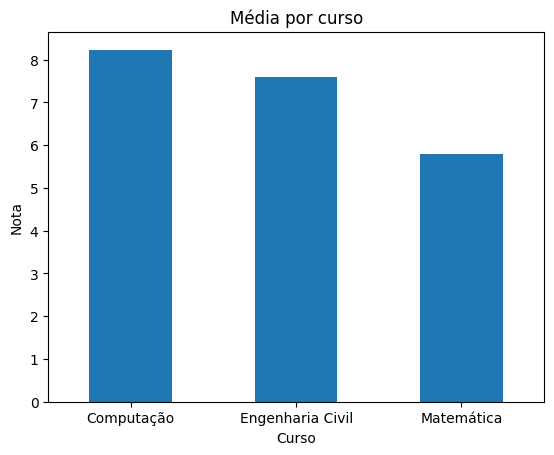

In [227]:
medias = df_alunos.groupby("curso")["nota"].mean()
ax = medias.plot(kind="bar", title="Média por curso", rot=0)
ax.set_ylabel("Nota")
ax.set_xlabel("Curso")
plt.show()

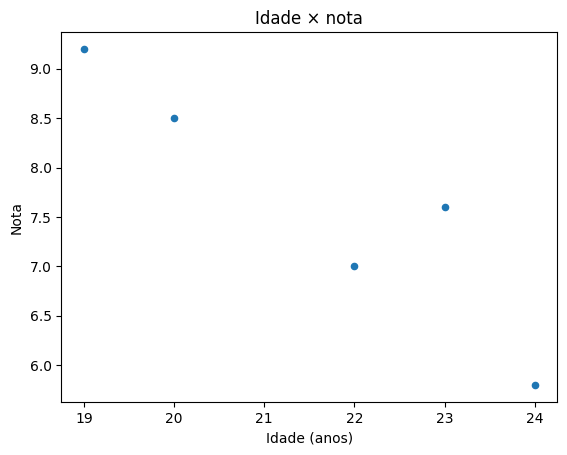

In [228]:
ax = df_alunos.plot(kind="scatter", x="idade", y="nota", title="Idade × nota")
ax.set_xlabel("Idade (anos)")
ax.set_ylabel("Nota")
plt.show()

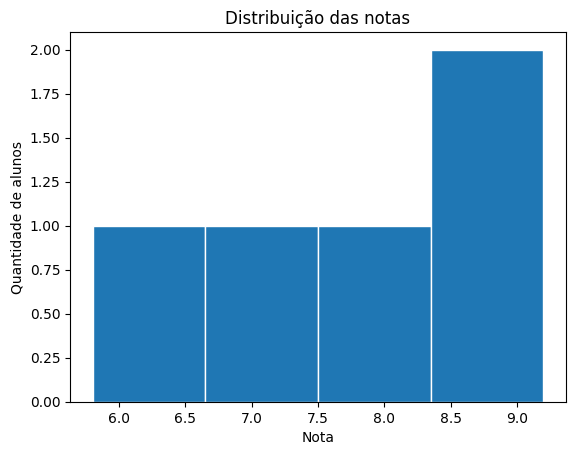

In [229]:
ax = df_alunos["nota"].plot(kind="hist", bins=4, title="Distribuição das notas", edgecolor="white")
ax.set_xlabel("Nota")
ax.set_ylabel("Quantidade de alunos")
plt.show()

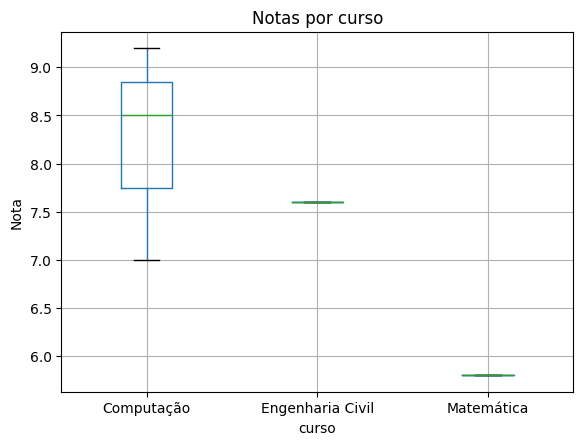

In [230]:
ax = df_alunos.boxplot(column="nota", by="curso")
ax.set_title("Notas por curso")
ax.set_ylabel("Nota")
plt.suptitle("")
plt.show()

### 7.3 Onde o Pandas entra no processo de ciência de dados

O fluxo clássico (adaptado de O'Neil e Schutt, *Doing Data Science*, O'Reilly, 2013):

**Realidade → Coleta de dados brutos → Processamento e limpeza → Dataset limpo → Análise exploratória → Modelos e algoritmos → Produto de dados / Comunicação → Tomada de decisão**

O Pandas atua principalmente nas etapas de **coleta, processamento, dataset limpo e análise exploratória**. A análise exploratória frequentemente devolve o trabalho para a etapa de processamento: limpeza e exploração se alimentam mutuamente.

**Exemplo:** o mesmo dado passando de "bruto" a "limpo" e depois a "explorado".

In [231]:
# dados brutos
bruto = pd.DataFrame({"nome": [" ana", "BRUNO", "Bruno"], "nota": ["8,5", "7,0", "7,0"]})

# processamento e limpeza
dataset_limpo = (bruto
    .assign(nome=bruto["nome"].str.strip().str.title(),
            nota=pd.to_numeric(bruto["nota"].str.replace(",", ".")))
    .drop_duplicates())

# análise exploratória
print(dataset_limpo)
print()
print(dataset_limpo["nota"].describe())

    nome  nota
0    Ana   8.5
1  Bruno   7.0

count    2.00000
mean     7.75000
std      1.06066
min      7.00000
25%      7.37500
50%      7.75000
75%      8.12500
max      8.50000
Name: nota, dtype: float64


---
## 8. Prática

### 8.1 Estudo de caso: do CSV ao gráfico

O script abaixo segue as cinco etapas do fluxo de análise e produz dois artefatos reutilizáveis: um gráfico em PNG e uma tabela-resumo em CSV.

- A limpeza vem **antes** da análise, e a ordem importa: normalizar nomes antes de remover duplicados.
- A mediana foi usada no preenchimento por ser menos sensível a valores extremos.
- Somar uma coluna booleana conta os `True`: é assim que `aprovados` é calculado.

Ele lê o arquivo `alunos.csv` criado na seção 3.1.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   nome    6 non-null      object 
 1   curso   6 non-null      object 
 2   idade   6 non-null      int64  
 3   nota    5 non-null      float64
 4   cidade  6 non-null      object 
dtypes: float64(1), int64(1), object(3)
memory usage: 372.0+ bytes
           idade      nota
count   6.000000  5.000000
mean   21.500000  7.620000
std     1.870829  1.319848
min    19.000000  5.800000
25%    20.250000  7.000000
50%    21.500000  7.600000
75%    22.750000  8.500000
max    24.000000  9.200000
                     media  aprovados
curso                                
Computação        8.233333          3
Engenharia Civil  7.600000          2
Matemática        5.800000          0


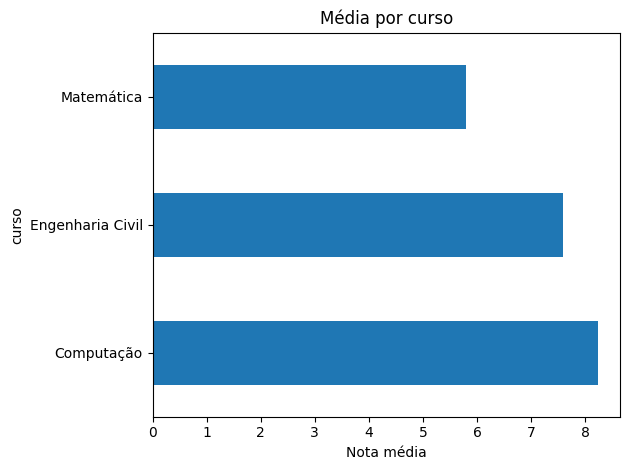

In [232]:
# 1. leitura
dados = pd.read_csv("alunos.csv", sep=";", decimal=",")

# 2. exploração
dados.info()
print(dados.describe())

# 3. limpeza
dados["nome"] = dados["nome"].str.strip().str.title()
dados = dados.drop_duplicates(subset=["nome", "curso"])
dados["nota"] = pd.to_numeric(dados["nota"], errors="coerce")
dados["nota"] = dados["nota"].fillna(dados["nota"].median())
dados = dados[dados["idade"].between(15, 90)]

# 4. análise
dados["aprovado"] = dados["nota"] >= 7
resumo = dados.groupby("curso").agg(media=("nota", "mean"),
                                    aprovados=("aprovado", "sum"))
print(resumo.sort_values("media", ascending=False))

# 5. visualização e exportação
ax = resumo["media"].plot(kind="barh", title="Média por curso")
ax.set_xlabel("Nota média")
plt.tight_layout()
plt.savefig("media_por_curso.png")
plt.show()
resumo.to_csv("resumo_cursos.csv")

### 8.2 Boas práticas e armadilhas comuns

**1. Evite laços sobre linhas.** Prefira operações vetorizadas a `for` com `iterrows()`.

In [233]:
grande = pd.DataFrame({"nota": np.random.default_rng(1).uniform(0, 10, 20_000)})

inicio = time.perf_counter()
for i, linha in grande.iterrows():          # lento
    grande.loc[i, "dobro_lento"] = linha["nota"] * 2
t_lento = time.perf_counter() - inicio

inicio = time.perf_counter()
grande["dobro"] = grande["nota"] * 2        # rápido
t_rapido = time.perf_counter() - inicio

print(f"iterrows:   {t_lento:.3f} s")
print(f"vetorizado: {t_rapido:.5f} s")

iterrows:   0.777 s
vetorizado: 0.00031 s


**2. Não encadeie atribuições.** `df[df["nota"] < 6]["nota"] = 6` não altera o `df` original: a atribuição acontece em uma cópia temporária. Com o Copy-on-Write do Pandas 3, isso nunca funciona, e o Pandas emite um aviso. Use um único `loc`.

In [234]:
teste = df_alunos.copy()
teste[teste["nota"] < 6]["nota"] = 6        # NÃO funciona: altera uma cópia
print("Encadeado:", teste.loc[5, "nota"])

teste.loc[teste["nota"] < 6, "nota"] = 6    # forma correta
print("Com loc:  ", teste.loc[5, "nota"])

Encadeado: 5.8
Com loc:   6.0


/var/folders/55/d7lt90h1619_87y17196mzdc0000gn/T/ipykernel_16769/2076217926.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  teste[teste["nota"] < 6]["nota"] = 6        # NÃO funciona: altera uma cópia


**3. Atribua o resultado.** Métodos como `dropna`, `fillna` e `rename` retornam um novo objeto. Prefira `df = df.dropna()` a `inplace=True`.

In [235]:
copia = df_alunos.copy()
copia.dropna()                     # resultado descartado
print("Sem atribuir:", copia.shape)

copia = copia.dropna()             # resultado guardado
print("Atribuindo:  ", copia.shape)

Sem atribuir: (6, 5)
Atribuindo:   (5, 5)


**4. Confira os tipos logo após a leitura.** Números lidos como texto quebram médias e ordenações silenciosamente.

In [236]:
texto = pd.Series(["10", "9", "100"])
print("Ordenando texto:  ", texto.sort_values().tolist())
print("Ordenando números:", texto.astype(int).sort_values().tolist())

Ordenando texto:   ['10', '100', '9']
Ordenando números: [9, 10, 100]


**5. Encadeie métodos para legibilidade.**

In [237]:
resultado = (
    df_alunos.dropna(subset=["nota"])
      .query("idade < 23")
      .groupby("curso")["nota"].mean()
      .sort_values()
)
resultado

curso
Computação    8.233333
Name: nota, dtype: float64

### 8.3 Exercícios propostos

Use o DataFrame `df` de alunos apresentado neste notebook. Escreva sua solução na célula abaixo de cada enunciado.

**Exercício 1.** Mostre quantas linhas e colunas o DataFrame possui e quais são os tipos de cada coluna.

In [238]:
# Seu código aqui

**Exercício 2.** Liste os alunos de Teresina com nota maior ou igual a 8, exibindo apenas nome e nota.

In [239]:
# Seu código aqui

**Exercício 3.** Crie a coluna `faixa_etaria` com os valores "até 20" e "acima de 20" e calcule a média de notas em cada faixa.

In [240]:
# Seu código aqui

**Exercício 4.** Calcule, por cidade, a quantidade de alunos e a maior nota, ordenando pela quantidade.

In [241]:
# Seu código aqui

**Exercício 5.** Gere um histograma das notas e um gráfico de dispersão de idade × nota. O que você observa?

In [242]:
# Seu código aqui

### 8.4 Referências e próximos passos

**Leituras recomendadas**
- Documentação oficial e guia do usuário: https://pandas.pydata.org/docs/
- Tutorial "10 minutes to pandas", na mesma documentação
- McKinney, W. *Python for Data Analysis*, 3ª ed., O'Reilly, 2022. Versão aberta em https://wesmckinney.com/book/
- O'Neil, C.; Schutt, R. *Doing Data Science*. O'Reilly, 2013

**Próximos tópicos**
- Séries temporais: `resample`, `rolling`, fusos horários
- Remodelagem: `melt`, `pivot`, `stack`, MultiIndex
- Visualização estatística com Seaborn
- Pré-processamento para aprendizado de máquina com scikit-learn
- Dados maiores que a memória com Polars e DuckDB

**Datasets abertos para praticar:** dados.gov.br, Kaggle e os microdados do INEP.